# Data efficiency: learning curves, a power law, and what pretraining buys

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/4_data_and_hardware/03_data_efficiency.ipynb) &nbsp; Guide note: [guide-data-efficiency](https://www.matthewwnuk.com/guide-data-efficiency.html)

How much data does a policy need? The honest answer is a curve. This notebook measures one on the toy
reaching task, fits it, and then asks the question that motivates foundation models: how much does
training on other layouts first reduce the data needed in a new one?

The whole notebook takes a few minutes: it trains about fifty small policies.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import copy, numpy as np, matplotlib.pyplot as plt
from guide_utils import toy, style
style.use(); starts, targets = toy.test_set(300)

## A learning curve

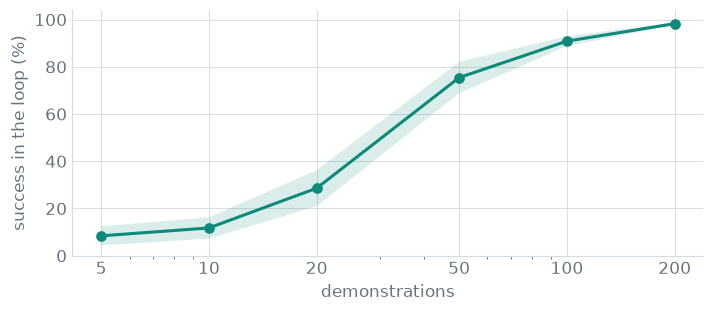

['8%', '12%', '29%', '75%', '91%', '98%']


In [3]:
counts = [5, 10, 20, 50, 100, 200]
success = np.array([[toy.rollout(toy.Policy(seed=s).fit(*toy.demonstrations(np.random.default_rng(1000 * s + n), n, "absolute")), starts, targets, "absolute") for n in counts] for s in range(4)])
mean = success.mean(0); plt.figure(figsize=(7.4, 2.9)); plt.fill_between(counts, (mean - success.std(0)) * 100, (mean + success.std(0)) * 100, alpha=0.15); plt.plot(counts, mean * 100, marker="o")
plt.xscale("log"); plt.xticks(counts, counts); plt.ylim(0, 104); plt.xlabel("demonstrations"); plt.ylabel("success in the loop (%)"); plt.show(); print([f"{v:.0%}" for v in mean])

## The shape of the curve

Plot the failure rate on log axes. A straight line means a power law: failure is proportional to
N to the power of minus alpha. The exponent summarises data efficiency in one number.

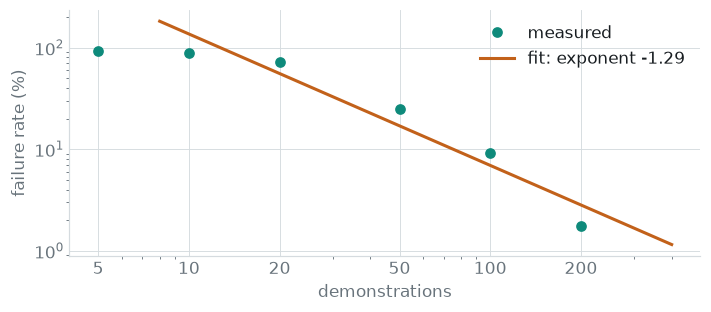

halving the failure rate takes 1.71 times the data
extrapolated demonstrations for 99% success: about 445


In [4]:
fail = 1 - mean; use = (np.array(counts) >= 10) & (fail > 0); slope, intercept = np.polyfit(np.log(np.array(counts)[use]), np.log(fail[use]), 1)
x = np.linspace(8, 400, 50); plt.figure(figsize=(7.4, 2.9)); plt.plot(counts, fail * 100, "o", label="measured"); plt.plot(x, np.exp(intercept) * x ** slope * 100, label=f"fit: exponent {slope:.2f}")
plt.xscale("log"); plt.yscale("log"); plt.xticks(counts, counts); plt.xlabel("demonstrations"); plt.ylabel("failure rate (%)"); plt.legend(); plt.show()
print(f"halving the failure rate takes {2 ** (-1 / slope):.2f} times the data"); print(f"extrapolated demonstrations for 99% success: about {(0.01 / np.exp(intercept)) ** (1 / slope):.0f}")

The fit is an extrapolation from a handful of points on a toy problem. It describes a regime, not a law.

## What pretraining buys

Move the obstacle to a new place. One policy sees only demonstrations from the new layout. The other
was first trained on four other layouts, and is then adapted with the old data mixed in so it does not
forget. The policy sees absolute positions, so it cannot simply read off where the obstacle is.

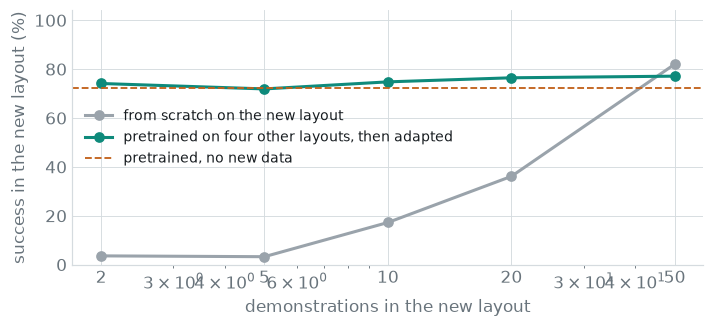

from scratch: ['4%', '3%', '17%', '36%', '82%']
pretrained:   ['74%', '72%', '75%', '76%', '77%']
pretrained with no new data: 72%


In [5]:
new, old = (0.62, 0.42), [(0.4, 0.6), (0.5, 0.5), (0.45, 0.4), (0.6, 0.58)]
def demos_at(centre, n, seed): toy.set_obstacle(centre); return toy.demonstrations(np.random.default_rng(seed), n, "absolute")
toy.set_obstacle(new); new_starts, new_targets = toy.test_set(300)
def evaluate(pol): toy.set_obstacle(new); return toy.rollout(pol, new_starts, new_targets, "absolute")

few = [2, 5, 10, 20, 50]; scratch, adapted, zero = [], [], []
for seed in range(3):
    Xp, Yp = map(np.concatenate, zip(*[demos_at(c, 60, seed * 10 + i) for i, c in enumerate(old)])); base = toy.Policy(seed=seed, max_iter=1200).fit(Xp, Yp); zero.append(evaluate(base)); row_s, row_a = [], []
    for n in few:
        Xn, Yn = demos_at(new, n, 500 + seed * 10 + n); row_s.append(evaluate(toy.Policy(seed=seed, max_iter=1200).fit(Xn, Yn)))
        ft = copy.deepcopy(base); ft.net.set_params(warm_start=True, max_iter=300, learning_rate_init=5e-4); reps = max(1, len(Xp) // (4 * len(Xn)))
        ft.fit(np.concatenate([Xn] * reps + [Xp[::4]]), np.concatenate([Yn] * reps + [Yp[::4]])); row_a.append(evaluate(ft))
    scratch.append(row_s); adapted.append(row_a)
toy.set_obstacle((0.5, 0.5)); scratch, adapted = np.mean(scratch, 0) * 100, np.mean(adapted, 0) * 100
plt.figure(figsize=(7.4, 3)); plt.plot(few, scratch, marker="o", color=style.GREY, label="from scratch on the new layout"); plt.plot(few, adapted, marker="o", color=style.TEAL, label="pretrained on four other layouts, then adapted")
plt.axhline(np.mean(zero) * 100, color=style.ORANGE, ls="--", lw=1.2, label="pretrained, no new data"); plt.xscale("log"); plt.xticks(few, few); plt.ylim(0, 104); plt.xlabel("demonstrations in the new layout"); plt.ylabel("success in the new layout (%)"); plt.legend(fontsize=9); plt.show()
print("from scratch:", [f"{v:.0f}%" for v in scratch]); print("pretrained:  ", [f"{v:.0f}%" for v in adapted]); print(f"pretrained with no new data: {np.mean(zero):.0%}")

Pretraining buys a starting level. With two demonstrations, the pretrained policy is already useful and
the one trained from scratch is not. The pretrained curve is also nearly flat: adapted conservatively,
it gains little from the new data, and training from scratch catches up once there is enough.

## Things to try

- Pretrain on one layout instead of four. How much of the benefit comes from variety?
- Adapt without mixing in the old data. Does the new layout improve faster, and what happens to the old ones?
- Give the policy relative inputs (`"relative"`). Why does the pretrained policy then need almost no adaptation?